# Final evaluation on the held-out test set

**This notebook is the only place the test set is used.** Everything below was fixed *before* looking at test results:

| Decision | Choice | Decided from |
|---|---|---|
| Models | Tuned **random forest** and tuned **gradient boosting**, plus the majority-class baseline, for both tasks | Val (2022) results in `outcome_pred/12`, `length_of_stay/12` |
| Hyperparameters | The tuned settings saved in `*/results/*_tuned.json` | Inner split (fit < 2021, score 2021) |
| Training data | **All intakes before 2023** (train + val), animal-grouped | Standard practice once settings are fixed |
| Test data | Animals first seen 2023-01-01 → 2025-02-03 (intakes after that are too recent to have reliable outcomes) | `utils.time_group_split` |
| Metrics | Outcome: accuracy, macro-F1, per-class precision/recall, PR-AUC, at-risk screen. Length of stay: accuracy, macro-F1, QWK, per-class recall. 95% bootstrap CIs (1,000 resamples of test **animals**). | README conventions |
| Extra checks | Species subgroups; `has_name` ablation for the random forest | Write-up caveats |

No model or setting is changed after seeing these numbers.

In [1]:
import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, f1_score, cohen_kappa_score, average_precision_score,
                             ConfusionMatrixDisplay)
from sklearn.pipeline import Pipeline

sys.path.append(str(Path.cwd().parent))
import utils

ROOT = Path.cwd().parent
RESULTS_DIR = Path("results"); RESULTS_DIR.mkdir(exist_ok=True)
ep = utils.load_austin_episodes()

def final_split(df):
    """Train = everything before 2023 (train + val), test = the usual held-out test set."""
    trv, _, te = utils.time_group_split(df, val_start=utils.TEST_START, test_start=utils.TEST_START)
    _, _, te_default = utils.time_group_split(df)
    assert set(te["episode_id"]) == set(te_default["episode_id"]), "test set must match the original"
    return trv, te

TASKS = {
    "outcome": dict(df=utils.model_frame(ep, "outcome"), target="outcome_group", labels=utils.OUTCOME_CLASSES,
                    ordinal=False, results=ROOT / "outcome_pred" / "results"),
    "length of stay": dict(df=utils.model_frame(ep, "los"), target="los_bin", labels=utils.LOS_BIN_LABELS,
                           ordinal=True, results=ROOT / "length_of_stay" / "results"),
}
for name, t in TASKS.items():
    t["train"], t["test"] = final_split(t["df"])
    print(f"{name:15s} train (<2023) {len(t['train']):,} rows | test {len(t['test']):,} rows, "
          f"{t['test']['intake_dt'].min().date()} → {t['test']['intake_dt'].max().date()}")

time_group_split: dropped 717 rows (0.5%) belonging to animals first seen in an earlier split
time_group_split: dropped 1,274 rows (0.8%) belonging to animals first seen in an earlier split
outcome         train (<2023) 136,477 rows | test 21,463 rows, 2023-01-01 → 2025-02-03
time_group_split: dropped 722 rows (0.5%) belonging to animals first seen in an earlier split


time_group_split: dropped 1,282 rows (0.8%) belonging to animals first seen in an earlier split
length of stay  train (<2023) 137,862 rows | test 21,835 rows, 2023-01-01 → 2025-02-03


In [2]:
def tuned(est, results_dir, slug):
    return utils.with_params(est, json.loads((results_dir / f"{slug}_tuned.json").read_text())["best_params"])

for t in TASKS.values():
    t["models"] = {
        "Majority baseline": DummyClassifier(strategy="most_frequent"),
        "Random forest (tuned)": tuned(RandomForestClassifier(n_jobs=-1, random_state=utils.SEED), t["results"], "random_forest"),
        "Gradient boosting (tuned)": tuned(HistGradientBoostingClassifier(random_state=utils.SEED), t["results"], "gradient_boosting"),
    }
    t["val_json"] = {"Majority baseline": "majority_class_baseline", "Random forest (tuned)": "random_forest_tuned",
                     "Gradient boosting (tuned)": "gradient_boosting_tuned"}
pd.DataFrame({task: {m: str(e.get_params().get("class_weight", "")) + " | " +
                     ", ".join(f"{k}={v}" for k, v in json.loads((t["results"] / f"{t['val_json'][m]}.json").read_text()).get("best_params", {}).items())
                     for m, e in t["models"].items()} for task, t in TASKS.items()})

,outcome,length of stay
Majority baseline,|,|
Random forest (tuned),"balanced | n_estimators=300, min_samples_leaf=...","balanced | n_estimators=300, min_samples_leaf=..."
Gradient boosting (tuned),"None | class_weight=None, l2_regularization=0....","None | class_weight=None, l2_regularization=0...."


## Fit on all pre-2023 data, predict the test set

In [3]:
def fit(est, tr, target, feats=utils.FEATURES, binary=None):
    pre = utils.make_preprocessor(binary=binary) if binary is not None else utils.make_preprocessor()
    return Pipeline([("pre", pre), ("model", utils.with_params(est, {}))]).fit(tr[feats], tr[target])

for name, t in TASKS.items():
    t["pipes"], t["pred"], t["proba"] = {}, {}, {}
    for m, est in t["models"].items():
        t0 = time.time()
        p = fit(est, t["train"], t["target"])
        t["pipes"][m] = p
        t["pred"][m] = pd.Series(p.predict(t["test"][utils.FEATURES]), index=t["test"].index)
        t["proba"][m] = pd.DataFrame(p.predict_proba(t["test"][utils.FEATURES]), columns=p.classes_, index=t["test"].index)
        print(f"{name:15s} {m:28s} fitted in {time.time() - t0:.0f}s")

outcome         Majority baseline            fitted in 1s


outcome         Random forest (tuned)        fitted in 21s


outcome         Gradient boosting (tuned)    fitted in 167s


length of stay  Majority baseline            fitted in 0s


length of stay  Random forest (tuned)        fitted in 23s


length of stay  Gradient boosting (tuned)    fitted in 23s


## Headline results with 95% bootstrap confidence intervals

The CIs resample test **animals** with replacement (an animal's repeat stays stay together), 1,000 times.

In [4]:
rng = np.random.default_rng(utils.SEED)

def metric_fns(labels, ordinal):
    rank = {l: i for i, l in enumerate(labels)}
    fns = {"accuracy": lambda y, p, w: accuracy_score(y, p, sample_weight=w),
           "macro_f1": lambda y, p, w: f1_score(y, p, labels=labels, average="macro", sample_weight=w, zero_division=0)}
    if ordinal:
        fns["qwk"] = lambda y, p, w: cohen_kappa_score(y.map(rank), p.map(rank), weights="quadratic", sample_weight=w)
    return fns

def with_ci(y, p, groups, fns, n_boot=1000):
    codes, uniq = pd.factorize(groups)
    out = {}
    boots = {k: [] for k in fns}
    for _ in range(n_boot):
        w = np.bincount(rng.integers(0, len(uniq), len(uniq)), minlength=len(uniq))[codes]
        for k, f in fns.items():
            boots[k].append(f(y, p, w))
    for k, f in fns.items():
        lo, hi = np.percentile(boots[k], [2.5, 97.5])
        out[k] = f(y, p, None); out[f"{k}_lo"] = lo; out[f"{k}_hi"] = hi
    return out

rows = []
for name, t in TASKS.items():
    y, g = t["test"][t["target"]], t["test"]["animal_id"]
    fns = metric_fns(t["labels"], t["ordinal"])
    for m in t["models"]:
        rows.append({"task": name, "model": m, **with_ci(y, t["pred"][m], g, fns)})
headline = pd.DataFrame(rows).set_index(["task", "model"])
headline.to_csv(RESULTS_DIR / "test_headline_metrics.csv")

def fmt(r, k):
    return f"{r[k]:.3f} [{r[k + '_lo']:.3f}, {r[k + '_hi']:.3f}]" if pd.notna(r.get(k)) else "—"
pd.DataFrame({k: headline.apply(lambda r: fmt(r, k), axis=1) for k in ["accuracy", "macro_f1", "qwk"]})

accuracy  \
task           model                                             
outcome        Majority baseline          0.645 [0.639, 0.652]   
               Random forest (tuned)      0.675 [0.668, 0.681]   
               Gradient boosting (tuned)  0.719 [0.713, 0.725]   
length of stay Majority baseline          0.391 [0.384, 0.398]   
               Random forest (tuned)      0.465 [0.459, 0.472]   
               Gradient boosting (tuned)  0.494 [0.487, 0.500]   

                                                      macro_f1  \
task           model                                             
outcome        Majority baseline          0.196 [0.195, 0.197]   
               Random forest (tuned)      0.519 [0.509, 0.528]   
               Gradient boosting (tuned)  0.518 [0.506, 0.530]   
length of stay Majority baseline          0.141 [0.139, 0.142]   
               Random forest (tuned)      0.413 [0.405, 0.420]   
               Gradient boosting (tuned)  0.393 [0.385, 0.401]   

                                                           qwk  
task           model                                            
outcome        Majority baseline                             —  
               Random forest (tuned)                         —  
               Gradient boosting (tuned)                     —  
length of stay Majority baseline          0.000 [0.000, 0.000]  
               Random forest (tuned)      0.314 [0.300, 0.327]  
               Gradient boosting (tuned)  0.316 [0.304, 0.328]

## Val (2022) vs. test (2023–25): did the results hold up?

Val models were trained on data before 2022. Test models were trained on data before 2023, with the same settings.

In [5]:
rows = []
for name, t in TASKS.items():
    for m, slug in t["val_json"].items():
        v = json.loads((t["results"] / f"{slug}.json").read_text())
        r = headline.loc[(name, m)]
        row = {"task": name, "model": m, "val accuracy": v["accuracy"], "test accuracy": r["accuracy"],
               "val macro_f1": v["macro_f1"], "test macro_f1": r["macro_f1"]}
        if t["ordinal"]:
            row.update({"val qwk": v.get("qwk"), "test qwk": r["qwk"]})
        rows.append(row)
vt = pd.DataFrame(rows).set_index(["task", "model"])
vt.round(3)

val accuracy  test accuracy  \
task           model                                                    
outcome        Majority baseline                 0.604          0.645   
               Random forest (tuned)             0.646          0.675   
               Gradient boosting (tuned)         0.678          0.719   
length of stay Majority baseline                 0.432          0.391   
               Random forest (tuned)             0.483          0.465   
               Gradient boosting (tuned)         0.517          0.494   

                                          val macro_f1  test macro_f1  \
task           model                                                    
outcome        Majority baseline                 0.188          0.196   
               Random forest (tuned)             0.518          0.519   
               Gradient boosting (tuned)         0.482          0.518   
length of stay Majority baseline                 0.151          0.141   
               Random forest (tuned)             0.405          0.413   
               Gradient boosting (tuned)         0.383          0.393   

                                          val qwk  test qwk  
task           model                                         
outcome        Majority baseline              NaN       NaN  
               Random forest (tuned)          NaN       NaN  
               Gradient boosting (tuned)      NaN       NaN  
length of stay Majority baseline            0.000     0.000  
               Random forest (tuned)        0.342     0.314  
               Gradient boosting (tuned)    0.314     0.316

## Outcome: per-class results

In [6]:
t = TASKS["outcome"]; L = t["labels"]; y = t["test"][t["target"]]
rows = []
for m in t["models"]:
    rep = utils.classification_metrics(y, t["pred"][m], labels=L, verbose=False)
    for c in L:
        rows.append({"model": m, "class": c, "precision": rep[f"precision_{c}"], "recall": rep[f"recall_{c}"],
                     "PR-AUC": average_precision_score(y == c, t["proba"][m][c]) if m != "Majority baseline" else np.nan,
                     "base rate": (y == c).mean()})
per_class = pd.DataFrame(rows).set_index(["model", "class"])
per_class.to_csv(RESULTS_DIR / "test_outcome_per_class.csv")
per_class.drop(index="Majority baseline").round(3)

/var/folders/bq/q6bbfq_s68l_m1x6yxgvqnt80000gn/T/ipykernel_7457/3655997072.py:11: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  per_class.drop(index="Majority baseline").round(3)


precision  recall  PR-AUC  \
model                     class                                        
Random forest (tuned)     Adoption             0.812   0.732   0.855   
                          Transfer             0.562   0.532   0.622   
                          Return to Owner      0.427   0.767   0.507   
                          Euthanasia           0.173   0.272   0.161   
Gradient boosting (tuned) Adoption             0.777   0.847   0.866   
                          Transfer             0.614   0.489   0.647   
                          Return to Owner      0.522   0.573   0.537   
                          Euthanasia           0.385   0.110   0.183   

                                           base rate  
model                     class                       
Random forest (tuned)     Adoption             0.645  
                          Transfer             0.252  
                          Return to Owner      0.082  
                          Euthanasia           0.021  
Gradient boosting (tuned) Adoption             0.645  
                          Transfer             0.252  
                          Return to Owner      0.082  
                          Euthanasia           0.021

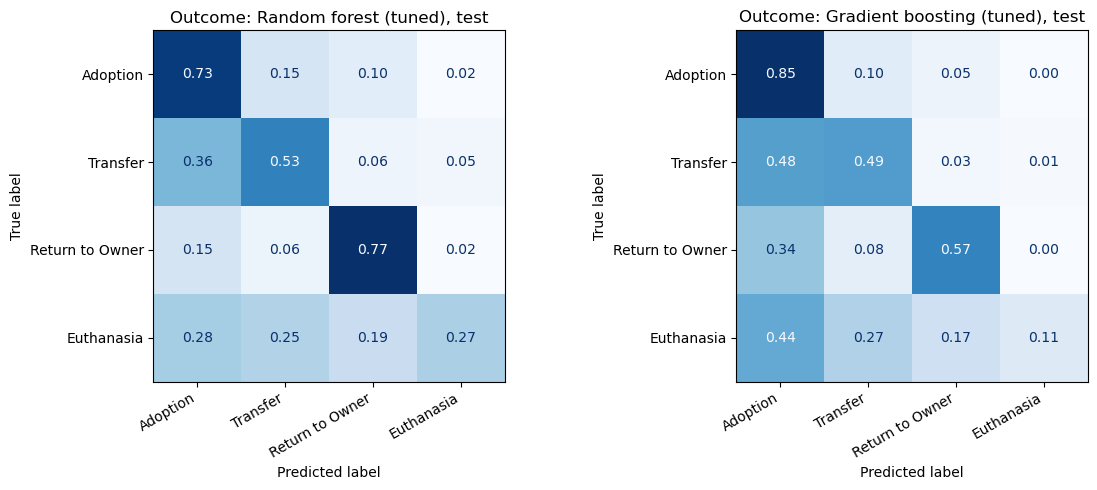

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, m in zip(axes, ["Random forest (tuned)", "Gradient boosting (tuned)"]):
    ConfusionMatrixDisplay.from_predictions(y, t["pred"][m], labels=L, normalize="true", values_format=".2f",
                                            cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"Outcome: {m}, test"); plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "test_outcome_confusion.png", dpi=150, bbox_inches="tight"); plt.show()

### The at-risk (euthanasia) flag as a screen on test

In [8]:
y_risk = (y == "Euthanasia").to_numpy()
rows = []
for m in ["Random forest (tuned)", "Gradient boosting (tuned)"]:
    s = t["proba"][m]["Euthanasia"].to_numpy(); order = np.argsort(-s)
    for top in [0.01, 0.02, 0.05, 0.10, 0.20]:
        n = int(len(s) * top); hit = y_risk[order[:n]].sum()
        rows.append({"model": m, "flag top": f"{top:.0%}", "flagged": n, "precision": hit / n, "recall": hit / y_risk.sum()})
screen = pd.DataFrame(rows).pivot(index="flag top", columns="model", values=["precision", "recall"]) \
    .reindex(["1%", "2%", "5%", "10%", "20%"])
print(f"at-risk animals in test: {y_risk.sum()} of {len(y_risk):,} ({y_risk.mean():.1%})")
screen.round(3)

at-risk animals in test: 453 of 21,463 (2.1%)


precision                        \
model    Gradient boosting (tuned) Random forest (tuned)   
flag top                                                   
1%                           0.322                 0.299   
2%                           0.233                 0.228   
5%                           0.161                 0.159   
10%                          0.116                 0.112   
20%                          0.077                 0.075   

                            recall                        
model    Gradient boosting (tuned) Random forest (tuned)  
flag top                                                  
1%                           0.152                 0.141  
2%                           0.221                 0.216  
5%                           0.382                 0.377  
10%                          0.552                 0.530  
20%                          0.733                 0.709

## Length of stay: per-bin recall

In [9]:
tl = TASKS["length of stay"]; yl = tl["test"][tl["target"]]
rec = pd.DataFrame({m: {c: utils.classification_metrics(yl, tl["pred"][m], labels=tl["labels"], verbose=False)[f"recall_{c}"]
                        for c in tl["labels"]} for m in tl["models"]}).T
display(rec.round(3))
yl.value_counts(normalize=True).reindex(tl["labels"]).round(3).rename("test bin share")

,<1 week,1-4 weeks,1-3 months,3+ months
Majority baseline,1.000,0.000,0.000,0.000
Random forest (tuned),0.476,0.522,0.434,0.232
Gradient boosting (tuned),0.722,0.423,0.308,0.102


los_bin
<1 week       0.391
1-4 weeks     0.313
1-3 months    0.235
3+ months     0.061
Name: test bin share, dtype: float64

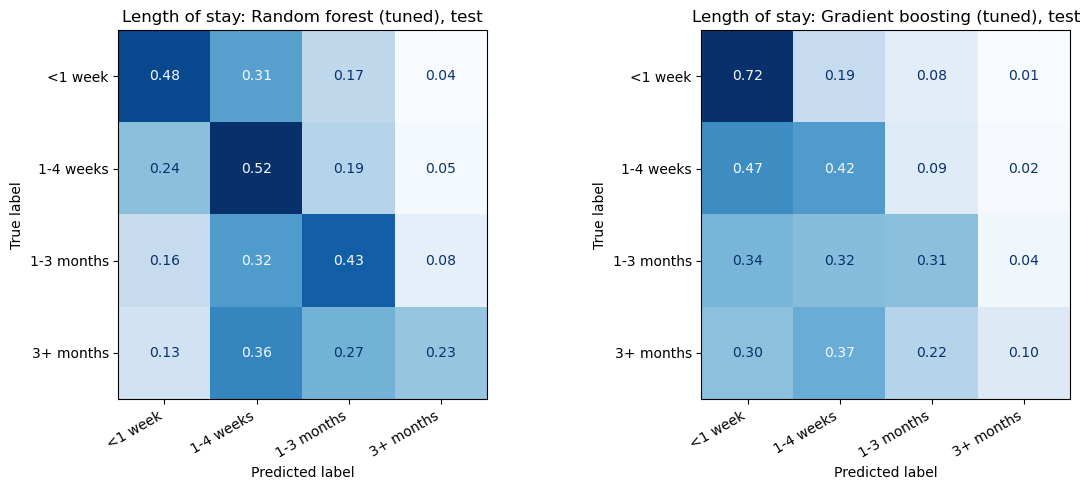

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, m in zip(axes, ["Random forest (tuned)", "Gradient boosting (tuned)"]):
    ConfusionMatrixDisplay.from_predictions(yl, tl["pred"][m], labels=tl["labels"], normalize="true", values_format=".2f",
                                            cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"Length of stay: {m}, test"); plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "test_los_confusion.png", dpi=150, bbox_inches="tight"); plt.show()

## Subgroups: dogs vs. cats (test)

In [11]:
rows = []
for name, tt in TASKS.items():
    yy = tt["test"][tt["target"]]
    for m in ["Random forest (tuned)", "Gradient boosting (tuned)"]:
        for s in ["Dog", "Cat"]:
            idx = tt["test"].index[tt["test"]["animal_type"] == s]
            rep = utils.classification_metrics(yy[idx], tt["pred"][m][idx], labels=tt["labels"], verbose=False)
            row = {"task": name, "model": m, "species": s, "n": len(idx), "accuracy": rep["accuracy"], "macro_f1": rep["macro_f1"]}
            if name == "outcome":
                row["at-risk recall"] = rep["recall_Euthanasia"]
            else:
                row["qwk"] = utils.quadratic_weighted_kappa(yy[idx], tt["pred"][m][idx], labels=tt["labels"])
            rows.append(row)
subgroups = pd.DataFrame(rows).set_index(["task", "model", "species"])
subgroups.to_csv(RESULTS_DIR / "test_subgroups.csv")
subgroups.round(3)

n  accuracy  macro_f1  \
task           model                     species                              
outcome        Random forest (tuned)     Dog       9899     0.634     0.459   
                                         Cat      11564     0.709     0.509   
               Gradient boosting (tuned) Dog       9899     0.684     0.468   
                                         Cat      11564     0.749     0.486   
length of stay Random forest (tuned)     Dog      10022     0.428     0.369   
                                         Cat      11813     0.497     0.402   
               Gradient boosting (tuned) Dog      10022     0.454     0.352   
                                         Cat      11813     0.527     0.401   

                                                  at-risk recall    qwk  
task           model                     species                         
outcome        Random forest (tuned)     Dog               0.062    NaN  
                                         Cat               0.425    NaN  
               Gradient boosting (tuned) Dog               0.026    NaN  
                                         Cat               0.172    NaN  
length of stay Random forest (tuned)     Dog                 NaN  0.297  
                                         Cat                 NaN  0.336  
               Gradient boosting (tuned) Dog                 NaN  0.295  
                                         Cat                 NaN  0.339

## `has_name` ablation on test (random forest)

In [12]:
bins_wo = [c for c in utils.BINARY_FEATURES if c != "has_name"]
feats_wo = utils.NUMERIC_FEATURES + bins_wo + utils.CATEGORICAL_FEATURES
rows = []
for name, tt in TASKS.items():
    m = "Random forest (tuned)"; yy = tt["test"][tt["target"]]
    p_wo = fit(tt["models"][m], tt["train"], tt["target"], feats=feats_wo, binary=bins_wo).predict(tt["test"][feats_wo])
    for label, p in [("with has_name", tt["pred"][m]), ("without has_name", p_wo)]:
        rep = utils.classification_metrics(yy, p, labels=tt["labels"], verbose=False)
        row = {"task": name, "features": label, "accuracy": rep["accuracy"], "macro_f1": rep["macro_f1"]}
        if name == "outcome":
            row.update({"RTO recall": rep["recall_Return to Owner"], "at-risk recall": rep["recall_Euthanasia"]})
        else:
            row["qwk"] = utils.quadratic_weighted_kappa(yy, pd.Series(p, index=yy.index), labels=tt["labels"])
        rows.append(row)
ablation = pd.DataFrame(rows).set_index(["task", "features"])
ablation.to_csv(RESULTS_DIR / "test_has_name_ablation.csv")
ablation.round(3)

accuracy  macro_f1  RTO recall  \
task           features                                           
outcome        with has_name        0.675     0.519       0.767   
               without has_name     0.665     0.499       0.593   
length of stay with has_name        0.465     0.413         NaN   
               without has_name     0.465     0.414         NaN   

                                 at-risk recall    qwk  
task           features                                 
outcome        with has_name              0.272    NaN  
               without has_name           0.296    NaN  
length of stay with has_name                NaN  0.314  
               without has_name             NaN  0.314

## Summary

**Headline** (test 2023-01-01 to 2025-02-03; fit on all pre-2023 intakes; 95% bootstrap CIs over test animals)

| Task | Model | Accuracy | Macro-F1 | QWK |
|---|---|---|---|---|
| Outcome | Majority baseline | 0.645 [0.639, 0.652] | 0.196 [0.195, 0.197] | - |
| Outcome | Random forest | 0.675 [0.668, 0.681] | 0.519 [0.509, 0.528] | - |
| Outcome | Gradient boosting | **0.719** [0.713, 0.725] | 0.518 [0.506, 0.530] | - |
| Length of stay | Majority baseline | 0.391 [0.384, 0.398] | 0.141 [0.139, 0.142] | 0.000 |
| Length of stay | Random forest | 0.465 [0.459, 0.472] | **0.413** [0.405, 0.420] | 0.314 [0.300, 0.327] |
| Length of stay | Gradient boosting | **0.494** [0.487, 0.500] | 0.393 [0.385, 0.401] | 0.316 [0.304, 0.328] |

- **Overall scores held.** Random forest macro-F1, val to test: outcome 0.518 to 0.519, length of stay 0.405 to 0.413. Length-of-stay QWK fell (0.342 to 0.314).
- **Outcome:** the models tie on macro-F1; gradient boosting is more accurate. **Length of stay:** random forest leads on macro-F1, gradient boosting on accuracy; QWK ties.
- **The at-risk (euthanasia) class got worse**, hidden by better Transfer recall (random forest 0.36 to 0.53). Random forest at-risk recall 0.37 to 0.27, precision 0.26 to 0.17, PR-AUC 0.24 to 0.16 (base rate 0.021). Gradient boosting test PR-AUC is 0.18.
- **Screen (random forest):** flagging the top 5% catches 38% at 16% precision (val: 46% at 20%); top 10% catches 53% at 11%.
- **Species:** at-risk recall is 43% for cats and 6% for dogs (random forest), so the gap persists.
- **`has_name` (random forest):** removing it changes outcome macro-F1 0.519 to 0.499 and Return to Owner recall 0.77 to 0.59; length of stay is unchanged (0.413 vs 0.414).

**Limits**
- Test was scored once, with models and settings fixed beforehand. It was not fully unseen: the EDA described all years, including 2023-25 outcome trends.
- Test contains animals first seen in 2023 or later, so results do not cover returning animals known from earlier years.
- CIs reflect test-set sampling only, not refitting or drift. Val vs test also differ in training data (pre-2022 vs pre-2023), so the change is not purely drift.
- Stays without an outcome are excluded, which slightly under-represents very long stays near the end of the window.